In [29]:
from pymongo import MongoClient
import pandas as pd

client = MongoClient("mongodb://localhost:27017/")
db = client["wsn_database"]
collection = db["sensor_data"]

data = list(collection.find())

df = pd.DataFrame(data)

df.head()


,_id,timestamp,id,count,temp,humidity,photo,solar
0,6a12dd96670cc6d0f35a83cd,2026-05-24 11:14:30.955,5,95,6994,1247,1309,1225
1,6a12ddaa670cc6d0f35a83ce,2026-05-24 11:14:50.372,5,96,7020,1229,1304,1217
2,6a12ddbd670cc6d0f35a83cf,2026-05-24 11:15:09.906,5,97,7045,1215,1306,1223
3,6a12ddd1670cc6d0f35a83d0,2026-05-24 11:15:29.446,5,98,7041,1202,1304,1221
4,6a12dde4670cc6d0f35a83d1,2026-05-24 11:15:48.987,5,99,7048,1216,1306,1221


In [30]:
df.describe()


,timestamp,id,count,temp,humidity,photo,solar
count,2007,2007.0,2007.000000,2007.000000,2007.000000,2007.000000,2007.000000
mean,2026-05-25 05:17:19.906051328,5.0,1577.984554,7308.236173,1096.168909,262.520179,151.594420
min,2026-05-24 11:14:30.955000,5.0,18.000000,6964.000000,961.000000,0.000000,0.000000
25%,2026-05-24 13:57:45.555500032,5.0,470.500000,7280.000000,1055.000000,55.000000,17.000000
50%,2026-05-25 10:25:10.507000064,5.0,1874.000000,7332.000000,1081.000000,102.000000,38.000000
75%,2026-05-25 13:12:00.066500096,5.0,2386.500000,7378.500000,1115.000000,268.000000,59.000000
max,2026-05-25 16:06:18.846000,5.0,2922.000000,7513.000000,1328.000000,1352.000000,1270.000000
std,NaN,0.0,963.325179,111.295337,70.773992,381.212042,340.566195


In [31]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

X = df[['count','humidity','photo','solar']]
y=df['temp']

X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2,random_state=42
)

model=LinearRegression()

model.fit(X_train,y_train)

prediction=model.predict(X_test)

print("Predicted temperatures:")
print(prediction[:10])


Predicted temperatures:
[7356.57249151 7167.23209823 7471.91175094 7308.38783512 7491.70190328
 7109.87521451 7404.93055845 7502.99440652 7169.86820756 7171.04182171]


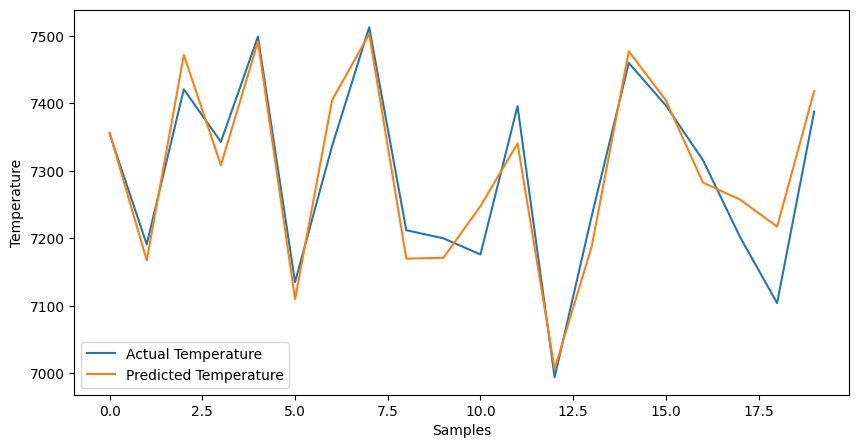

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(y_test.values[:20],label='Actual Temperature')
plt.plot(prediction[:20],label='Predicted Temperature')

plt.legend()
plt.xlabel("Samples")
plt.ylabel("Temperature")

plt.show()

In [33]:
len(df)

2007

In [34]:
from sklearn.metrics import mean_squared_error, r2_score

print("R²:", r2_score(y_test, prediction))
print("MSE:", mean_squared_error(y_test, prediction))

R²: 0.8472299009643605
MSE: 1698.0870849118437
